# How the patch-kNN anomaly check works (visual walkthrough)
Idea: learn **only what good looks like** from a few photos, then flag anything that doesn't match.
Run cells top to bottom. Uses MVTec *bottle* (eval data, in `data/mvtec`).

In [9]:
import glob, numpy as np, cv2, matplotlib.pyplot as plt
import pipeline as P
plt.rcParams["figure.dpi"] = 90
show = lambda im, ax=None: (ax or plt).imshow(cv2.cvtColor(im, cv2.COLOR_BGR2RGB))
CAT = "bottle"
train = sorted(glob.glob(f"data/mvtec/{CAT}/train/good/*.png"))
good = sorted(glob.glob(f"data/mvtec/{CAT}/test/good/*.png"))
bad = sorted(glob.glob(f"data/mvtec/{CAT}/test/broken_large/*.png")) + sorted(glob.glob(f"data/mvtec/{CAT}/test/contamination/*.png"))
be = P.OnnxDino(224)          # 224 px = 16x16 patch grid, fast to look at
print("grid:", be.grid, "x", be.grid, "=", be.grid**2, "patches per image")

grid: 16 x 16 = 256 patches per image


## 1. The Reference set (N = 5 good images)
This is all the system is ever told about 'normal'.

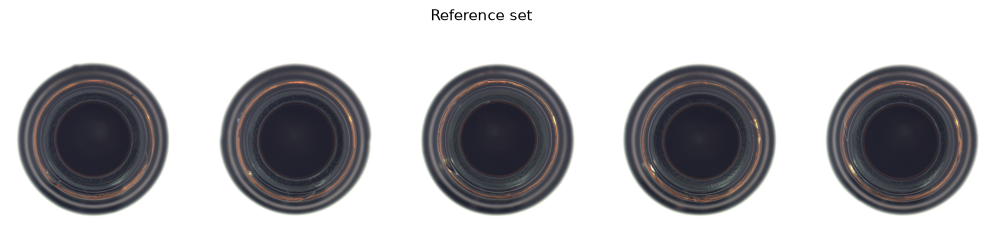

In [10]:
ref_paths = train[:5]
ref_imgs = [cv2.imread(p) for p in ref_paths]
fig, ax = plt.subplots(1, 5, figsize=(14, 3))
for a, im in zip(ax, ref_imgs): show(im, a); a.axis("off")
plt.suptitle("Reference set"); plt.show()

## 2. extract(): image → patch vectors
The image is resized and cut into a grid of 14×14-pixel patches; DINOv2 turns each patch into a 384-number vector.
Below: the grid drawn on an image, and the feature matrix shape.

features: (256, 384) (patches x dims), dtype float32


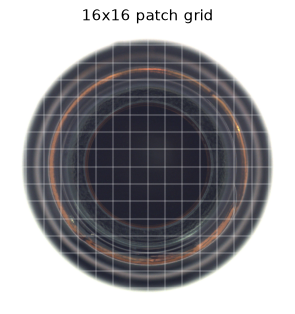

In [11]:
im = ref_imgs[0]; f = be.extract(im)
print("features:", f.shape, "(patches x dims), dtype", f.dtype)
g = be.grid; s = im.shape[0] / g
plt.figure(figsize=(4, 4)); show(im)
for i in range(1, g): plt.axhline(i * s, c="w", lw=.3); plt.axvline(i * s, c="w", lw=.3)
plt.title(f"{g}x{g} patch grid"); plt.axis("off"); plt.show()

## 3. Enrollment: the memory bank + leave-one-out threshold
Bank = every patch from every reference image stacked together. 
Threshold: score each reference image against a bank made from the *others*; take the worst, multiply by a margin.

memory bank: (1280, 384) = 2.0 MB
LOO scores per reference image: [0.697 0.597 0.582 0.558 0.638]
worst = 0.697  ->  threshold = worst x 1.1 = 0.767


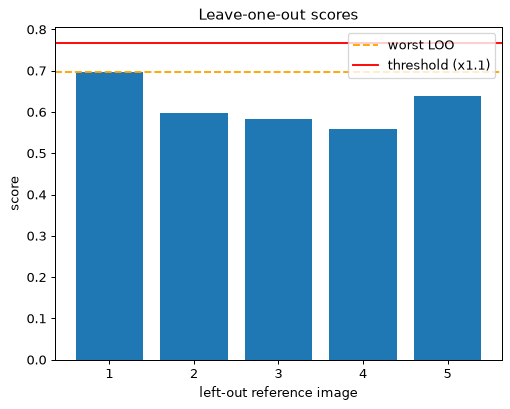

In [12]:
feats = [be.extract(im) for im in ref_imgs]
bank = np.concatenate(feats); print("memory bank:", bank.shape, f"= {bank.nbytes/1e6:.1f} MB")
MARGIN = 1.1
thr, loo = P.loo_threshold(feats, margin=MARGIN, floor=0)
print("LOO scores per reference image:", np.round(loo, 3))
print(f"worst = {max(loo):.3f}  ->  threshold = worst x {MARGIN} = {thr:.3f}")
plt.bar(range(1, 6), loo); plt.axhline(max(loo), c="orange", ls="--", label="worst LOO")
plt.axhline(thr, c="r", label=f"threshold (x{MARGIN})"); plt.xlabel("left-out reference image"); plt.ylabel("score")
plt.legend(); plt.title("Leave-one-out scores"); plt.show()

## 4. Scoring one image: per-patch distance → heatmap → max
For each patch, distance to its **nearest** bank patch. Good patch → small. Defect patch → big. Image score = the biggest.

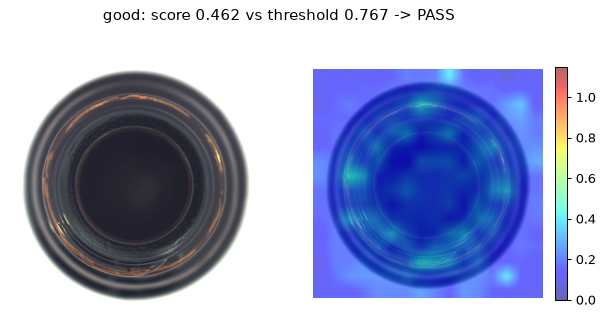

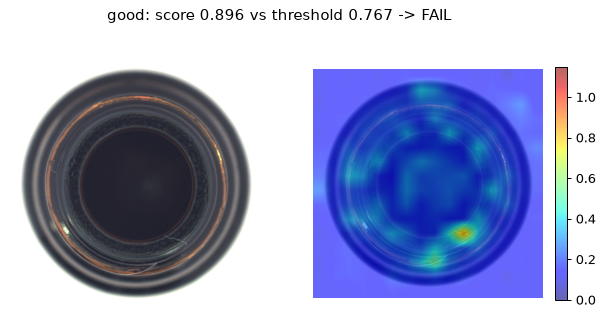

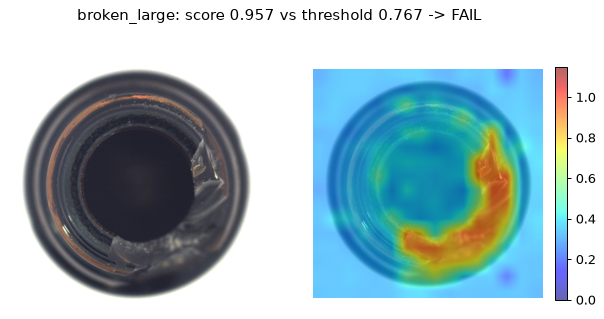

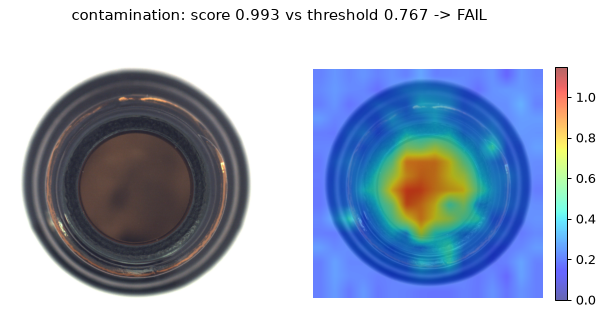

In [13]:
def view(path, title=None):
    im = cv2.imread(path); sc, hm = P.score(be.extract(im), bank, be.grid, (im.shape[1], im.shape[0]))
    fig, ax = plt.subplots(1, 2, figsize=(8, 4)); show(im, ax[0]); ax[0].axis("off")
    show(im, ax[1]); h = ax[1].imshow(hm, alpha=.6, cmap="jet", vmin=0, vmax=thr * 1.5); ax[1].axis("off")
    plt.colorbar(h, ax=ax[1], fraction=.046)
    verdict = "FAIL" if sc > thr else "PASS"
    plt.suptitle(f"{title or path.split('/')[-2]}: score {sc:.3f} vs threshold {thr:.3f} -> {verdict}"); plt.show()
view(good[0], "good"); view(good[1], "good"); view(bad[0]); view(bad[-1])

## 5. Why it works: score distributions of good vs anomalous test images

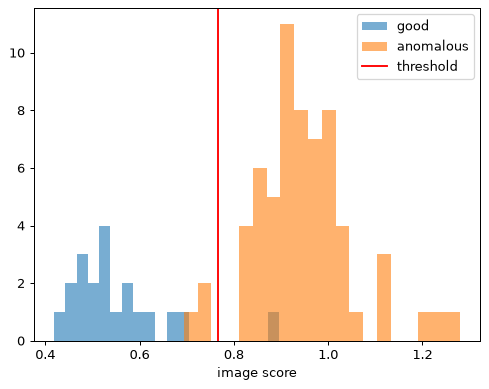

false alarms: 5%   misses: 5%


In [14]:
gs = [P.score(be.extract(cv2.imread(p)), bank, be.grid)[0] for p in good]
allbad = sorted(glob.glob(f"data/mvtec/{CAT}/test/*/*.png")); allbad = [p for p in allbad if "/good/" not in p]
bs = [P.score(be.extract(cv2.imread(p)), bank, be.grid)[0] for p in allbad]
plt.hist(gs, 20, alpha=.6, label="good"); plt.hist(bs, 20, alpha=.6, label="anomalous")
plt.axvline(thr, c="r", label="threshold"); plt.legend(); plt.xlabel("image score"); plt.show()
print(f"false alarms: {np.mean(np.array(gs) > thr):.0%}   misses: {np.mean(np.array(bs) <= thr):.0%}")

## 6. The margin trade-off (the thing that can't be tuned in the field)
Sweep the margin on the same data: low margin = more false alarms, high margin = more misses.

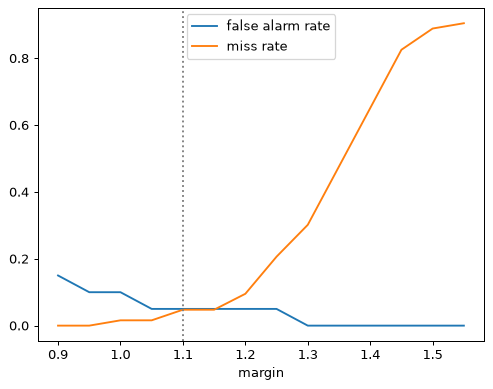

In [15]:
ms = np.arange(0.9, 1.6, .05); worst = max(loo)
fa = [np.mean(np.array(gs) > worst * m) for m in ms]; miss = [np.mean(np.array(bs) <= worst * m) for m in ms]
plt.plot(ms, fa, label="false alarm rate"); plt.plot(ms, miss, label="miss rate"); plt.axvline(1.1, c="gray", ls=":")
plt.xlabel("margin"); plt.legend(); plt.show()

## 7. Position shift
Slide a good image sideways and watch the score creep towards the threshold. (Bottle is round so it barely cares; try `CAT = 'hazelnut'` or `'screw'` at the top and rerun.)

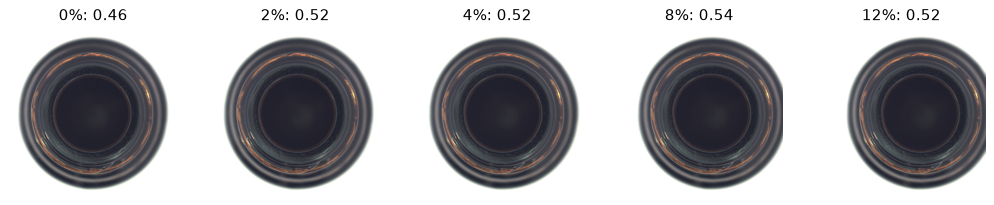

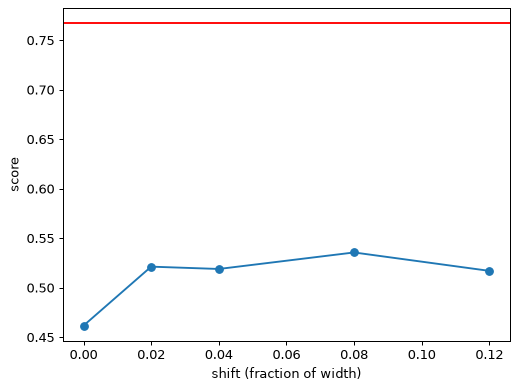

In [16]:
def shift(im, f):
    M = np.float32([[1, 0, f * im.shape[1]], [0, 1, 0]])
    return cv2.warpAffine(im, M, (im.shape[1], im.shape[0]), borderMode=cv2.BORDER_REPLICATE)
fs = [0, .02, .04, .08, .12]; im0 = cv2.imread(good[0]); out = []
fig, ax = plt.subplots(1, len(fs), figsize=(14, 3))
for a, f in zip(ax, fs):
    sh = shift(im0, f); sc = P.score(be.extract(sh), bank, be.grid)[0]; out.append(sc); show(sh, a); a.axis("off"); a.set_title(f"{f:.0%}: {sc:.2f}")
plt.show()
plt.plot(fs, out, "o-"); plt.axhline(thr, c="r"); plt.xlabel("shift (fraction of width)"); plt.ylabel("score"); plt.show()